# Flaviviridae glycoproteins: recognising distant homologues across viral groups

Candidate panel for Figure 1, next to the SCOPe benchmark (panel c). ESM3Di is meant for viral proteins
whose relatives have diverged beyond what amino-acid alignment can reliably detect, the *twilight zone*
of about 20-35% pairwise identity and below. This notebook first shows where the *Flaviviridae* envelope
glycoproteins of Figure 2b sit relative to that zone, and then asks the question it motivates: **do
pairwise searches recognise two glycoproteins from different viral groups as the same protein, as
opposed to a different protein?**

**Data.** The 626 E, E1 and E2 envelope glycoproteins of `flaviviridae_trees.ipynb`, with the groups of
Mifsud et al. as six-letter codes (e.g. `E1HPHV`: protein E1, group HPHV). The 13 unclassified
sequences (codes ending in `UN`) are left out, since their group is unknown. E, E1 and E2 are different
proteins, so every pair is of one of three kinds:

| Pairs | Relationship |
|---|---|
| same group | close homologues |
| same protein, other group | **distant homologues** |
| other protein | not homologous |

**Searches.** All-vs-all, every pair aligned:

| Method | Search |
|---|---|
| ESM3Di, ProstT5 | Foldseek on predicted 3Di + amino acids (the `esm3di foldtree` runs of `flaviviridae_trees.ipynb`) |
| AlphaFold2 | Foldseek on 3Di from the AlphaFold2 structures (same notebook) |
| MMseqs2 | amino-acid alignment, no prefilter (`--prefilter-mode 2`) and no E-value cut-off, like the MMseqs2 baseline of panel c |

**Scores.** The E-value, by which Foldseek and MMseqs2 rank hits and on which panel c is based, is the
main score; the bitscore and fident (the share of identical amino acids over the alignment columns,
the score behind the FoldTree distances) are reported alongside.

**Uncertainty.** Pairs share sequences and are not independent, so the 95% intervals of the AUCs come
from `BOOTSTRAPS` bootstrap samples of the *sequences*; a pair is weighted by how often both of its
sequences were drawn. All methods use the same samples, so differences between methods are paired: an
interval of a difference that excludes 0 means the ranking holds across resampled datasets.

**Running.** Needs the foldtree runs in `OUTPUT_DIR` (not tracked), the MAFFT alignments of
`../pairwise_identity/pairwise_identity.ipynb` (run that first) and, on the first run, MMseqs2 on the
PATH (on the cluster: `module load gcc/11.5.0 mmseqs2/18-8cc5c` before starting Jupyter). Writes
`results/flaviviridae_pair_identity.csv`, `results/flaviviridae_distant_homologs_*.csv`,
`results/flaviviridae_group_auc.csv` and `figures/flaviviridae_distant_homologs.{pdf,png}`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

sys.path.insert(0, "../shared")  # code shared by the phylogeny analyses
from monophyly import glycoprotein_labels

sys.path.insert(0, "../../../../benchmarks")   # shared style of the paper figures
from pub_style import METHOD_COLOURS, MUTED_TEXT, WIDTH_DOUBLE, add_panel_labels, save_pub, use_pub_style

use_pub_style()

INPUT_DIR = Path("inputs")
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/flaviviridae")   # all-vs-all searches (not tracked)
MSA_DIR = Path("/scratch/fweikert/phylogeny/pairwise_identity")  # MAFFT alignments of pairwise_identity.ipynb
RESULTS_DIR = Path("results")
FIGURE_DIR = Path("figures")
MMSEQS = "mmseqs"
THREADS = 4
BOOTSTRAPS = 200
TWILIGHT = (20, 35)          # the conventional twilight zone of pairwise amino-acid identity, as in pairwise_identity.ipynb
DETECTION_EVALUE = 1e-3      # E-value below which a hit counts as detected

# Method -> all-vs-all search of the glycoproteins (E, E1 and E2 together)
SEARCHES = {
    "AlphaFold2": OUTPUT_DIR / "af2_fullglyco" / "allvall_1.csv",
    "ESM3Di": OUTPUT_DIR / "esm3di_fullglyco" / "allvall_1.csv",
    "ProstT5": OUTPUT_DIR / "prostt5_fullglyco" / "allvall_1.csv",
    "MMseqs2": OUTPUT_DIR / "mmseqs_fullglyco" / "allvall_1.csv",
}
# Score -> (column of the search output, value of a pair without an alignment); higher is more similar
SCORES = {"E-value": ("evalue", np.inf), "bitscore": ("bits", 0.0), "fident": ("fident", 0.0)}
COLUMNS = ["query", "target", "fident", "alnlen", "mismatch", "gapopen", "qstart", "qend", "tstart", "tend",
           "evalue", "bits"]
# 3Di from structures is the structural reference, drawn like Foldseek in panel c
COLOURS = {**METHOD_COLOURS, "AlphaFold2": METHOD_COLOURS["Foldseek"]}
PROTEINS = {"E0": "E", "E1": "E1", "E2": "E2"}   # protein code of the six-letter labels -> name

labels = glycoprotein_labels({p: INPUT_DIR / f"refolded_fullglyco_{p}_aa.fas" for p in ("E", "E1", "E2")})
group = {tip: label[:6] for tip, label in labels.items() if label[4:6] != "UN"}
protein = {tip: code[:2] for tip, code in group.items()}
print(f"{len(group)} of {len(labels)} sequences, {len(set(group.values()))} groups")
print(pd.Series(group).groupby(pd.Series(protein)).nunique().rename(index=PROTEINS).rename("groups").to_dict())

613 of 626 sequences, 14 groups
{'E': 8, 'E1': 3, 'E2': 3}


## 1. Where the twilight zone is

Pairwise amino-acid identity of every pair of the same protein, read off the MAFFT alignment of that
protein (`pairwise_identity.ipynb`, the identities of Supplementary Table 1): the fraction of alignment
columns where both sequences have a residue and the residues are identical. Pairs of different proteins
are not homologous and have no meaningful alignment, so they have no identity here.

In [2]:
def read_fasta(path):
    # [(name, sequence)], the name cut at the first space and without ".pdb" (the tip names)
    records, name, parts = [], None, []
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            if name is not None:
                records.append((name, "".join(parts)))
            name, parts = line[1:].split()[0].removesuffix(".pdb"), []
        elif line.strip():
            parts.append(line.strip().upper())
    return records + ([(name, "".join(parts))] if name is not None else [])


def pairwise_identity(alignment):
    # {(a, b): identity in %} over the columns where both sequences have a residue, as in pairwise_identity.ipynb
    records = read_fasta(alignment)
    names = [name for name, _ in records]
    columns = np.array([list(sequence) for _, sequence in records], dtype="S1")
    residue = ~np.isin(columns, [b"-", b"."])
    identity = {}
    for i in range(len(names)):
        both = residue[i + 1:] & residue[i]
        values = 100 * ((columns[i + 1:] == columns[i]) & both).sum(1) / both.sum(1)
        identity.update({tuple(sorted((names[i], other))): value for other, value in zip(names[i + 1:], values)})
    return identity


identity = {}
for code, name in PROTEINS.items():
    identity.update(pairwise_identity(MSA_DIR / f"{name}.msa"))

rows = [{"protein": PROTEINS[protein[a]], "a": a, "b": b, "identity": value,
         "kind": "same group" if group[a] == group[b] else "same protein, other group"}
        for (a, b), value in identity.items() if a in group and b in group]
pair_identity = pd.DataFrame(rows)
pair_identity.round(2).to_csv(RESULTS_DIR / "flaviviridae_pair_identity.csv", index=False)


def describe(values):
    return pd.Series({"pairs": len(values), "median identity (%)": np.median(values),
                      f"below {TWILIGHT[0]}% (%)": 100 * np.mean(values < TWILIGHT[0]),
                      f"{TWILIGHT[0]}-{TWILIGHT[1]}% (%)": 100 * np.mean((values >= TWILIGHT[0]) & (values < TWILIGHT[1])),
                      f"{TWILIGHT[1]}% or more (%)": 100 * np.mean(values >= TWILIGHT[1])})


identity_table = pd.concat([
    pair_identity.groupby(["kind", "protein"])["identity"].apply(describe).unstack(),
    pair_identity.groupby("kind")["identity"].apply(describe).unstack().assign(protein="all").set_index("protein", append=True),
]).sort_index()
identity_table["pairs"] = identity_table["pairs"].astype(int)
identity_table.round(1)

pairs  median identity (%)  below 20% (%)  \
kind                      protein                                              
same group                E         5819                 41.2           30.2   
                          E1        7042                 27.0            9.5   
                          E2        7009                 22.8           32.7   
                          all      19870                 26.8           23.7   
same protein, other group E        21911                 14.8           83.2   
                          E1       10724                 17.0           70.5   
                          E2       10569                 17.1           86.3   
                          all      43204                 15.9           80.8   

                                   20-35% (%)  35% or more (%)  
kind                      protein                               
same group                E              10.7             59.2  
                          E1             62.6             28.0  
                          E2             43.5             23.8  
                          all            40.6             35.6  
same protein, other group E              10.7              6.1  
                          E1             29.5              0.0  
                          E2             13.7              0.0  
                          all            16.1              3.1

The two kinds of pairs sit on either side of the twilight zone. Three quarters of the pairs of the same
group are at 20% identity or more, where amino-acid alignment still finds most homologues. Four fifths
of the pairs of the same protein from different groups are below 20%, under the twilight zone, where
amino-acid alignment is expected to lose sensitivity. Recognising those distant pairs as homologous is
the question of the rest of this notebook.

## 2. MMseqs2 all-vs-all search

Every pair is aligned (no prefilter) and every alignment is kept (`-e inf`); the output has the
columns of the Foldseek searches of the foldtree workflow.

In [3]:
mmseqs_out = SEARCHES["MMseqs2"]
fasta = INPUT_DIR / "refolded_fullglyco_aa.fas"
if mmseqs_out.exists():
    print(f"Exists, skipping: {mmseqs_out}")
else:
    mmseqs_out.parent.mkdir(parents=True, exist_ok=True)
    cmd = [MMSEQS, "easy-search", str(fasta), str(fasta), str(mmseqs_out), str(mmseqs_out.parent / "tmp"),
           "--prefilter-mode", "2", "-e", "inf", "--max-seqs", "10000", "--threads", str(THREADS),
           "--format-output", ",".join(COLUMNS[:10] + ["evalue", "bits"])]
    print(" ".join(cmd))
    subprocess.run(cmd, check=True, stdout=subprocess.DEVNULL)

Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/mmseqs_fullglyco/allvall_1.csv


## 3. Pairs and scores

One alignment per unordered pair: the hit of the alphabetically first sequence against the second
(as in `flaviviridae_trees.ipynb`), else the reverse hit. A pair without either scores as unrelated
(fident and bitscore 0, E-value infinite).

In [4]:
ids = sorted(group)
pairs = pd.MultiIndex.from_tuples([(a, b) for i, a in enumerate(ids) for b in ids[i + 1:]], names=["a", "b"])
same = np.array([group[a] == group[b] for a, b in pairs])
same_protein = np.array([protein[a] == protein[b] for a, b in pairs])
distant = same_protein & ~same                       # distant homologues: same protein, other group
pair_protein = np.array([PROTEINS[protein[a]] if protein[a] == protein[b] else "" for a, b in pairs])
pair_identity_values = np.array([identity.get((a, b), np.nan) for a, b in pairs])
kind = np.select([same, same_protein], ["same group", "same protein, other group"], "other protein")


def pair_scores(path):
    # One row per pair in `pairs` with the columns of SCORES, and the number of pairs without an alignment
    table = pd.read_table(path, header=None, names=COLUMNS)
    for column in ("query", "target"):
        table[column] = table[column].str.replace(".pdb", "", regex=False)
    table = table[table["query"].isin(group) & table["target"].isin(group) & (table["query"] != table["target"])]
    q, t = table["query"].to_numpy(), table["target"].to_numpy()
    table = table.assign(a=np.where(q < t, q, t), b=np.where(q < t, t, q), forward=q < t)
    table = table.sort_values("forward", ascending=False, kind="stable").drop_duplicates(["a", "b"])
    table = table.set_index(["a", "b"]).reindex(pairs)
    n_missing = int(table["fident"].isna().sum())
    return pd.DataFrame({score: table[column].fillna(fill).to_numpy() for score, (column, fill) in SCORES.items()}), n_missing


scores, missing = {}, {}
for method, path in SEARCHES.items():
    scores[method], missing[method] = pair_scores(path)
print(f"{len(pairs)} pairs:", pd.Series(kind).value_counts().to_dict())
print("Pairs without an alignment:", missing)


def similarity(method, score):
    # Score of every pair, oriented so that higher means more similar
    values = scores[method][score].to_numpy()
    return -values if score == "E-value" else values

187578 pairs: {'other protein': 124504, 'same protein, other group': 43204, 'same group': 19870}
Pairs without an alignment: {'AlphaFold2': 0, 'ESM3Di': 0, 'ProstT5': 0, 'MMseqs2': 0}


## 4. Distant homologues against other proteins

Positives are the pairs of the same protein from different groups, negatives the pairs of different
proteins; pairs of the same group are left out. The ROC curve lowers a score threshold and plots the
share of distant homologues above it (true positive rate) against the share of other-protein pairs
above it (false positive rate). Its area, the AUC, is the chance that a random pair of distant
homologues scores higher than a random pair of different proteins (ties count half).

In [5]:
def weighted_auc(rank, n_ranks, positive, weights):
    # Mann-Whitney AUC of the positive vs the other pairs; rank orders the values, ties count half
    pos = np.bincount(rank, weights=weights * positive, minlength=n_ranks)
    neg = np.bincount(rank, weights=weights * ~positive, minlength=n_ranks)
    below = np.cumsum(neg) - neg
    return float(np.sum(pos * (below + neg / 2)) / (pos.sum() * neg.sum()))


ranks = {}
for method in SEARCHES:
    for score in SCORES:
        unique, rank = np.unique(similarity(method, score), return_inverse=True)
        ranks[method, score] = rank, len(unique)

# Bootstrap samples of the sequences, shared by every AUC of this notebook
position = {s: i for i, s in enumerate(ids)}
first = np.array([position[a] for a, _ in pairs])
second = np.array([position[b] for _, b in pairs])
rng = np.random.default_rng(0)
samples = [rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids))) for _ in range(BOOTSTRAPS)]
sample_weights = [(counts[first] * counts[second]).astype(float) for counts in samples]


def auc_with_bootstrap(positive, mask):
    # {(method, score): (AUC, bootstrap AUCs)} of `positive` against the other pairs within `mask`
    return {key: (weighted_auc(rank, n, positive, mask.astype(float)),
                  np.array([weighted_auc(rank, n, positive, w * mask) for w in sample_weights]))
            for key, (rank, n) in ranks.items()}


def auc_tables(results, comparisons):
    table = pd.DataFrame([
        {"score": score, "method": method, "AUC": value, "CI low": np.percentile(boot, 2.5),
         "CI high": np.percentile(boot, 97.5)}
        for score in SCORES for method in SEARCHES for value, boot in [results[method, score]]
    ]).set_index(["score", "method"])
    differences = pd.DataFrame([
        {"score": score, "difference": f"{a} - {b}",
         "AUC difference": results[a, score][0] - results[b, score][0],
         "CI low": np.percentile(results[a, score][1] - results[b, score][1], 2.5),
         "CI high": np.percentile(results[a, score][1] - results[b, score][1], 97.5),
         "share > 0": (results[a, score][1] > results[b, score][1]).mean()}
        for score in SCORES for a, b in comparisons
    ]).set_index(["score", "difference"])
    return table, differences


COMPARISONS = [("ESM3Di", "ProstT5"), ("ESM3Di", "MMseqs2"), ("AlphaFold2", "ESM3Di"), ("AlphaFold2", "MMseqs2")]
distant_results = auc_with_bootstrap(distant, ~same)
distant_auc, distant_differences = auc_tables(distant_results, COMPARISONS)
distant_auc.round(4).to_csv(RESULTS_DIR / "flaviviridae_distant_homologs_auc.csv")
distant_differences.round(4).to_csv(RESULTS_DIR / "flaviviridae_distant_homologs_auc_differences.csv")
display(distant_auc["AUC"].unstack("score")[list(SCORES)].loc[list(SEARCHES)].round(3))
display(distant_differences.round(3))

score,E-value,bitscore,fident
method,,,
AlphaFold2,0.976,0.974,0.628
ESM3Di,0.875,0.866,0.589
ProstT5,0.846,0.839,0.537
MMseqs2,0.774,0.769,0.379


AUC difference  CI low  CI high  share > 0
score    difference                                                      
E-value  ESM3Di - ProstT5               0.029   0.014    0.045        1.0
         ESM3Di - MMseqs2               0.100   0.077    0.120        1.0
         AlphaFold2 - ESM3Di            0.101   0.085    0.119        1.0
         AlphaFold2 - MMseqs2           0.202   0.183    0.220        1.0
bitscore ESM3Di - ProstT5               0.027   0.012    0.042        1.0
         ESM3Di - MMseqs2               0.097   0.074    0.116        1.0
         AlphaFold2 - ESM3Di            0.108   0.090    0.127        1.0
         AlphaFold2 - MMseqs2           0.205   0.184    0.223        1.0
fident   ESM3Di - ProstT5               0.052   0.039    0.065        1.0
         ESM3Di - MMseqs2               0.209   0.184    0.237        1.0
         AlphaFold2 - ESM3Di            0.040   0.027    0.055        1.0
         AlphaFold2 - MMseqs2           0.249   0.226    0.277        1.0

### Sensitivity up to the first false positive

The measure of panel c, per query: all other sequences are ranked by E-value, and the sensitivity is
the share of the query's distant homologues that score better than its best-scoring sequence of a
different protein (sequences of the query's own group are ignored). Averaged over the queries; the
interval is from bootstrap samples of the queries.

In [6]:
def sensitivity_to_first_fp(method):
    # Per query: share of its distant homologues with an E-value below that of its best other-protein hit
    n = len(ids)
    matrix = np.full((n, n), -np.inf)
    values = similarity(method, "E-value")
    matrix[first, second] = values
    matrix[second, first] = values
    codes = np.array([group[s] for s in ids])
    proteins = np.array([protein[s] for s in ids])
    result = np.full(n, np.nan)
    for i in range(n):
        homologue = (proteins == proteins[i]) & (codes != codes[i])
        other = proteins != proteins[i]
        if homologue.any():
            result[i] = np.mean(matrix[i, homologue] > matrix[i, other].max())
    return result


per_query = pd.DataFrame({method: sensitivity_to_first_fp(method) for method in SEARCHES}, index=ids).dropna()
rng = np.random.default_rng(2)
draws = [rng.integers(0, len(per_query), len(per_query)) for _ in range(BOOTSTRAPS)]
boot_means = {method: np.array([per_query[method].to_numpy()[d].mean() for d in draws]) for method in SEARCHES}
sensitivity = pd.DataFrame([
    {"method": method, "queries": len(per_query), "mean sensitivity": per_query[method].mean(),
     "CI low": np.percentile(boot_means[method], 2.5), "CI high": np.percentile(boot_means[method], 97.5)}
    for method in SEARCHES]).set_index("method")
sensitivity.round(4).to_csv(RESULTS_DIR / "flaviviridae_distant_homologs_sensitivity.csv")
sensitivity.round(3)

,queries,mean sensitivity,CI low,CI high
method,,,,
AlphaFold2,613,0.848,0.833,0.863
ESM3Di,613,0.461,0.436,0.485
ProstT5,613,0.342,0.320,0.360
MMseqs2,613,0.345,0.322,0.362


### By sequence identity

The distant homologues split by their amino-acid identity (section 1), against all pairs of different
proteins. For each identity bin: the AUC by E-value, and the share of pairs detected at
E < `DETECTION_EVALUE`. The false positives at that threshold, among the pairs of different proteins,
are counted below the table.

In [7]:
BINS = {f"below {TWILIGHT[0]}%": (0, TWILIGHT[0]), f"{TWILIGHT[0]}-{TWILIGHT[1]}%": TWILIGHT,
        f"{TWILIGHT[1]}% or more": (TWILIGHT[1], 101)}
rows = []
for label, (low, high) in BINS.items():
    in_bin = distant & (pair_identity_values >= low) & (pair_identity_values < high)
    mask = in_bin | ~same_protein
    for method in SEARCHES:
        rank, n = ranks[method, "E-value"]
        boot = [weighted_auc(rank, n, in_bin, w * mask) for w in sample_weights]
        rows.append({"identity": label, "method": method, "pairs": int(in_bin.sum()),
                     "AUC": weighted_auc(rank, n, in_bin, mask.astype(float)),
                     "CI low": np.percentile(boot, 2.5), "CI high": np.percentile(boot, 97.5),
                     "detected (%)": 100 * np.mean(scores[method]["E-value"].to_numpy()[in_bin] < DETECTION_EVALUE)})
by_identity = pd.DataFrame(rows).set_index(["identity", "method"])
by_identity.round(4).to_csv(RESULTS_DIR / "flaviviridae_distant_homologs_by_identity.csv")
display(by_identity[["AUC", "detected (%)"]].unstack("method").loc[list(BINS)].round(3))
print("Pairs per bin:", by_identity["pairs"].groupby(level="identity").first().loc[list(BINS)].to_dict())
print(f"Pairs of different proteins with E < {DETECTION_EVALUE:g}:",
      {method: int((scores[method]["E-value"].to_numpy()[~same_protein] < DETECTION_EVALUE).sum()) for method in SEARCHES},
      f"of {int((~same_protein).sum())}")

AUC                        detected (%)                    \
method      AlphaFold2 ESM3Di MMseqs2 ProstT5   AlphaFold2   ESM3Di  MMseqs2   
identity                                                                       
below 20%        0.972  0.861   0.731   0.827       56.751   36.384   14.948   
20-35%           0.994  0.920   0.950   0.910       86.133   40.609   72.108   
35% or more      1.000  1.000   1.000   1.000      100.000  100.000  100.000   

                      
method       ProstT5  
identity              
below 20%     16.662  
20-35%        31.427  
35% or more  100.000

Pairs per bin: {'below 20%': 34900, '20-35%': 6959, '35% or more': 1345}
Pairs of different proteins with E < 0.001: {'AlphaFold2': 0, 'ESM3Di': 38, 'ProstT5': 22, 'MMseqs2': 0} of 124504


## 5. Figure

**a**, amino-acid identity of the pairs of the same protein, by whether the two sequences are of the
same group, with the twilight zone shaded. **b**, ROC curves of distant homologues against pairs of
different proteins, ranked by E-value (method colours and AUC table as in panel c of Figure 1).
**c**, share of distant homologues detected at E < 10⁻³, by amino-acid identity. The ROC curves of every
score are saved to `results/flaviviridae_distant_homologs_roc.csv`.

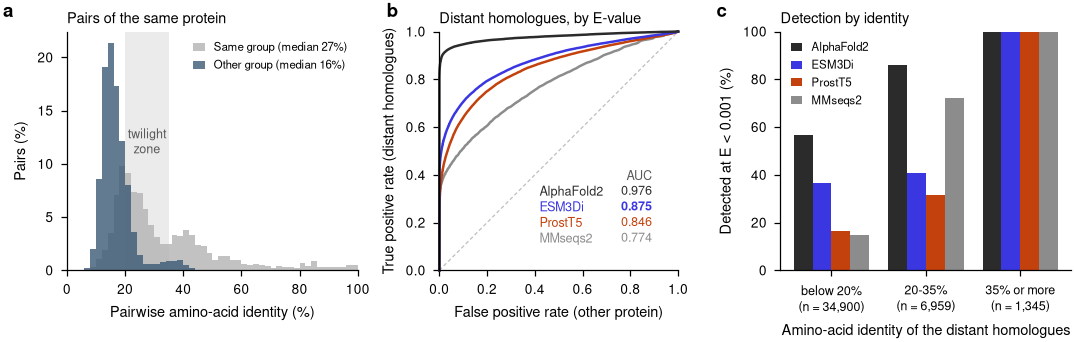

In [8]:
def roc_curve(values, positive):
    # False and true positive rates over all thresholds, most similar first
    order = np.argsort(-values, kind="stable")
    values, positive = values[order], positive[order]
    last = np.r_[np.diff(values) != 0, True]   # one point per distinct threshold
    tp, fp = np.cumsum(positive)[last], np.cumsum(~positive)[last]
    return np.r_[0, fp / fp[-1]], np.r_[0, tp / tp[-1]]


roc = pd.concat([
    pd.DataFrame(dict(zip(("score", "method", "fpr", "tpr"),
                          (score, method, *roc_curve(similarity(method, score)[~same], distant[~same])))))
    for score in SCORES for method in SEARCHES
])
roc.round(5).to_csv(RESULTS_DIR / "flaviviridae_distant_homologs_roc.csv", index=False)

KIND_COLOURS = {"same group": "0.7", "same protein, other group": "#3C5A75"}
KIND_LABELS = {"same group": "Same group", "same protein, other group": "Other group"}

fig, axes = plt.subplots(1, 3, figsize=(WIDTH_DOUBLE, WIDTH_DOUBLE / 3.1), layout="constrained")

# a: identity of the pairs of the same protein
ax = axes[0]
edges = np.arange(0, 102, 2)
ax.axvspan(*TWILIGHT, color="0.92", lw=0, zorder=0)
ax.text(np.mean(TWILIGHT), 0.6, "twilight\nzone", transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=6, color=MUTED_TEXT)
for kind_name, colour in KIND_COLOURS.items():
    values = pair_identity.loc[pair_identity["kind"] == kind_name, "identity"]
    ax.stairs(100 * np.histogram(values, bins=edges)[0] / len(values), edges, fill=True, color=colour,
              alpha=0.8, lw=0, label=f"{KIND_LABELS[kind_name]} (median {np.median(values):.0f}%)")
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.set_xlabel("Pairwise amino-acid identity (%)")
ax.set_ylabel("Pairs (%)")
ax.legend(loc="upper right", bbox_to_anchor=(1, 1), fontsize=5.5, frameon=False, handlelength=1)
ax.set_title("Pairs of the same protein")

# b: ROC by E-value
ax = axes[1]
aucs = distant_auc.loc["E-value", "AUC"].sort_values(ascending=False)
ax.plot([0, 1], [0, 1], color="0.75", lw=0.6, ls=(0, (3, 2)))
for method in aucs.index[::-1]:
    curve = roc[(roc["score"] == "E-value") & (roc["method"] == method)]
    ax.plot(curve["fpr"], curve["tpr"], color=COLOURS[method], clip_on=False)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_box_aspect(1)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))
ax.set_xlabel("False positive rate (other protein)")
ax.set_ylabel("True positive rate (distant homologues)")
ax.set_title("Distant homologues, by E-value")
for row, (method, value) in enumerate(aucs.items()):
    kwargs = dict(xycoords="axes fraction", textcoords="offset points", va="top", fontsize=6, color=COLOURS[method])
    ax.annotate(method, (0.42, 0.42), xytext=(0, -7.5 * (row + 1)), ha="left", **kwargs)
    ax.annotate(f"{value:.3f}", (0.42, 0.42), xytext=(54, -7.5 * (row + 1)), ha="right",
                fontweight="bold" if method == "ESM3Di" else "normal", **kwargs)
ax.annotate("AUC", (0.42, 0.42), xycoords="axes fraction", xytext=(54, 0), textcoords="offset points",
            ha="right", va="top", fontsize=6, color="0.35")

# c: detection by identity
ax = axes[2]
detected = by_identity["detected (%)"].unstack("method")[list(SEARCHES)].loc[list(BINS)]
width = 0.8 / len(SEARCHES)
for k, method in enumerate(SEARCHES):
    ax.bar(np.arange(len(BINS)) + (k - (len(SEARCHES) - 1) / 2) * width, detected[method], width,
           color=COLOURS[method], label=method)
counts = by_identity["pairs"].unstack("method").iloc[:, 0].loc[list(BINS)]
ax.set_xticks(np.arange(len(BINS)), [f"{label}\n(n = {n:,})" for label, n in counts.items()], fontsize=6)
ax.set_ylim(0, 100)
ax.set_xlabel("Amino-acid identity of the distant homologues")
ax.set_ylabel(f"Detected at E < {DETECTION_EVALUE:g} (%)")
ax.legend(loc="upper left", fontsize=5.5, frameon=False, handlelength=1)
ax.set_title("Detection by identity")

add_panel_labels(axes)
save_pub(fig, "flaviviridae_distant_homologs", FIGURE_DIR)
plt.show()

## 6. For comparison: close homologues within a protein

The complementary question at short range: pairs of the same group against pairs of the same protein
from other groups, i.e. how the scores rank close relatives above distant ones. Pairs of the same group are
mostly at 20% identity or more (section 1), the regime where amino-acid alignment is expected to do
well; fident is the score FoldTree builds its distances from.

In [9]:
group_results = auc_with_bootstrap(same, same_protein)
group_auc, group_differences = auc_tables(group_results, COMPARISONS)
group_auc.round(4).to_csv(RESULTS_DIR / "flaviviridae_group_auc.csv")
display(group_auc["AUC"].unstack("score")[list(SCORES)].loc[list(SEARCHES)].round(3))

score,E-value,bitscore,fident
method,,,
AlphaFold2,0.723,0.754,0.852
ESM3Di,0.669,0.659,0.830
ProstT5,0.713,0.701,0.824
MMseqs2,0.835,0.834,0.604


## 7. Summary

- **The twilight zone.** Pairs of the same *Flaviviridae* glycoprotein from different viral groups have a
  median amino-acid identity of 16%, and 81% of them are below 20%; pairs of the same group have a median
  of 27%.
- **Distant homologues against other proteins**, by E-value: AlphaFold2 0.976, ESM3Di 0.875, ProstT5 0.846,
  MMseqs2 0.774. ESM3Di is ahead of ProstT5 (difference 0.029, interval 0.014 to 0.045) and of MMseqs2
  (0.100, interval 0.077 to 0.120); bitscore gives the same ranking. In sensitivity up to the first false
  positive, the measure of panel c, ESM3Di recovers on average 46% of a query's distant homologues, against
  34% for ProstT5 and 35% for MMseqs2 (AlphaFold2: 85%).
- **By identity.** Below 20% identity, where most distant homologues are, ESM3Di detects 36% of the pairs at
  E < 10⁻³, against 17% for ProstT5 and 15% for MMseqs2 (AUC 0.861, 0.827 and 0.731). Between 20% and 35%,
  amino-acid alignment is still effective: MMseqs2 detects 72% (AUC 0.950), ESM3Di 41% (AUC 0.920). Above
  35% every method finds every pair. At E < 10⁻³ there are 38 false positives for ESM3Di and 22 for
  ProstT5 among 124,504 pairs of different proteins (0.03% and 0.02%), none for AlphaFold2 and MMseqs2.
- **Close homologues within a protein** (section 6), the complementary short-range question, are ranked
  best by amino-acid alignment scores (MMseqs2 E-value 0.835) and, among the 3Di methods, by fident
  (AlphaFold2 0.852, ESM3Di 0.830, ProstT5 0.824). Structure-aware search and sequence search are thus
  complementary: the gain from predicted 3Di lies in the distant homologues below the twilight zone.